In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

## RubyB - logistic regression model

In [37]:
from sklearn.model_selection import train_test_split
symptoms = ['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache']

missing_symptom = df[symptoms].isna().any(axis=1) # Rows where a symptom was never recorded (null) - this is different from "symptom absent" (0)
print(f"Dropping {missing_symptom.sum()} rows with a missing symptom value "
      f"({missing_symptom.mean():.2%} of data); rows with all-zero symptoms are kept: "
      f"{(df[symptoms].fillna(1).sum(axis=1) == 0).sum():,}")

covid_model_df = df.loc[~missing_symptom].copy() # New df copy to model with
covid_model_df['result'] = covid_model_df['corona_result']      # positive / negative / other (keeping all 3 to see how it looks)
covid_model_df = pd.concat(
    [covid_model_df[symptoms + ['result']],
     pd.get_dummies(covid_model_df['test_indication'], prefix='test_indication', dtype=int)], axis=1)
ti_cols = [c for c in covid_model_df.columns if c.startswith('test_indication')]

# 60 / 20 / 20, stratified on the 3-class result so every set has the same mix (incl. 'other')
# i.e., 60% train, 20% validation & 20% test
trainval, test = train_test_split(covid_model_df, test_size=0.20, random_state=42,
                                  stratify=covid_model_df['result'])
train, val = train_test_split(trainval, test_size=0.25, random_state=42, stratify=trainval['result'])

for name, part in [('train', train), ('val', val), ('test', test)]:
    print(name, len(part), part['result'].value_counts(normalize=True).round(4).to_dict())

Dropping 254 rows with a missing symptom value (0.09% of data); rows with all-zero symptoms are kept: 229,048
train 167156 {'negative': 0.9333, 'positive': 0.0527, 'other': 0.014}
val 55719 {'negative': 0.9333, 'positive': 0.0527, 'other': 0.014}
test 55719 {'negative': 0.9333, 'positive': 0.0527, 'other': 0.014}


In [38]:
covid_model_df.groupby('result')[symptoms + ti_cols].mean().T.round(3)

result,negative,other,positive
cough,0.135,0.169,0.448
fever,0.061,0.097,0.378
sore_throat,0.001,0.009,0.104
shortness_of_breath,0.001,0.007,0.079
head_ache,0.001,0.008,0.152
test_indication_Abroad,0.089,0.101,0.127
test_indication_Contact with confirmed,0.012,0.041,0.497
test_indication_Other,0.899,0.857,0.376


In [39]:
# Seeing what it would look to model based on reporting corona_result as;
# A: drop other, B: other counted as negative, C: 3-class (other kept as its own class)

# Helper functions for the three labels mentioned above:
def make_target(part, variant):
    """returns (rows, labels) for a training variant"""
    if variant == 'A: drop other':
        part = part[part['result'] != 'other']
        return part, (part['result'] == 'positive').astype(int)
    if variant == 'B: other = negative':
        return part, (part['result'] == 'positive').astype(int)
    if variant == 'C: 3-class (other kept)':
        return part, part['result']         # string labels

def eval_sets(part):
    """two evaluation populations"""
    pn = part[part['result'] != 'other']
    return {'pos/neg only': (pn, (pn['result'] == 'positive').astype(int)),
            'all rows (other = neg)': (part, (part['result'] == 'positive').astype(int))}

In [40]:
# Compare variants and feature sets on the validation set

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

feature_sets = {'symptoms only': symptoms, 'symptoms + test_indication': symptoms + ti_cols}
variants = ['A: drop other', 'B: other = negative', 'C: 3-class (other kept)']

def fit_predict(variant, cols, train_part, eval_part):
    Xtr, ytr = make_target(train_part, variant)
    clf = LogisticRegression(class_weight='balanced', max_iter=1000).fit(Xtr[cols], ytr)
    p = clf.predict_proba(eval_part[cols])
    pos_idx = list(clf.classes_).index(1 if variant != 'C: 3-class (other kept)' else 'positive')
    return p[:, pos_idx]

rows = []
for fs_name, cols in feature_sets.items():
    for v in variants:
        for ev_name, (ev_part, ev_y) in eval_sets(val).items():
            p = fit_predict(v, cols, train, ev_part)
            rows.append({'features': fs_name, 'trained on': v, 'evaluated on': ev_name,
                         'ROC-AUC': roc_auc_score(ev_y, p), 'PR-AUC': average_precision_score(ev_y, p)})
val_results = pd.DataFrame(rows)
val_results.pivot_table(index=['features', 'trained on'], columns='evaluated on',
                        values=['ROC-AUC', 'PR-AUC']).round(4)

PR-AUC  \
evaluated on                                       all rows (other = neg)   
features                   trained on                                       
symptoms + test_indication A: drop other                           0.5751   
                           B: other = negative                     0.5705   
                           C: 3-class (other kept)                 0.5616   
symptoms only              A: drop other                           0.3533   
                           B: other = negative                     0.3533   
                           C: 3-class (other kept)                 0.3467   

                                                                 \
evaluated on                                       pos/neg only   
features                   trained on                             
symptoms + test_indication A: drop other                 0.5822   
                           B: other = negative           0.5776   
                           C: 3-class (other kept)       0.5683   
symptoms only              A: drop other                 0.3581   
                           B: other = negative           0.3581   
                           C: 3-class (other kept)       0.3514   

                                                                  ROC-AUC  \
evaluated on                                       all rows (other = neg)   
features                   trained on                                       
symptoms + test_indication A: drop other                           0.8866   
                           B: other = negative                     0.8865   
                           C: 3-class (other kept)                 0.8861   
symptoms only              A: drop other                           0.7678   
                           B: other = negative                     0.7678   
                           C: 3-class (other kept)                 0.7674   

                                                                 
evaluated on                                       pos/neg only  
features                   trained on                            
symptoms + test_indication A: drop other                 0.8870  
                           B: other = negative           0.8869  
                           C: 3-class (other kept)       0.8864  
symptoms only              A: drop other                 0.7681  
                           B: other = negative           0.7681  
                           C: 3-class (other kept)       0.7677

In [44]:
# ^ In the code, 'symptoms + test_indication' means the five symptoms plus all three test_indication dummy columns: 
# test_indication_Abroad, test_indication_Contact with confirmed and test_indication_Other

threshold (from validation): 0.293
Test ROC-AUC: 0.8875 | PR-AUC: 0.5701
Test recall: 0.822 | precision: 0.228 | F1: 0.357


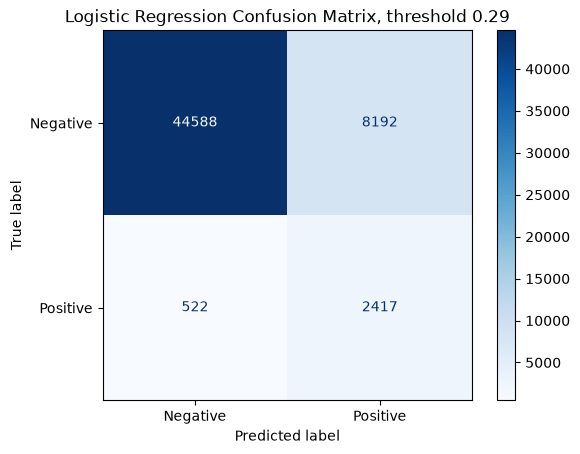

In [53]:
# Final model, threshold from validation, one look at test

from sklearn.metrics import (precision_recall_curve, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

cols = feature_sets['symptoms + test_indication']
FINAL = 'B: other = negative'            # <- can replace with whichever variant the team picks

Xtr, ytr = make_target(train, FINAL)
final = LogisticRegression(class_weight='balanced', max_iter=1000).fit(Xtr[cols], ytr)

# threshold chosen on the VALIDATION set (target recall 80%)
val_y = (val['result'] == 'positive').astype(int)
p_val = final.predict_proba(val[cols])[:, 1]
prec, rec, thr = precision_recall_curve(val_y, p_val)
ok = rec[:-1] >= 0.80
threshold = thr[ok][np.argmax(prec[:-1][ok])]
print('threshold (from validation):', round(threshold, 3))

# Look at the test set (all rows, other counted as not positive)
y_test_all = (test['result'] == 'positive').astype(int)
p_test = final.predict_proba(test[cols])[:, 1]
y_hat = (p_test >= threshold).astype(int)
print('Test ROC-AUC:', round(roc_auc_score(y_test_all, p_test), 4), '| PR-AUC:', round(average_precision_score(y_test_all, p_test), 4))
print('Test recall:', round(recall_score(y_test_all, y_hat), 3), '| precision:', round(precision_score(y_test_all, y_hat), 3), '| F1:', round(f1_score(y_test_all, y_hat), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test_all, y_hat), display_labels=['Negative', 'Positive']).plot(cmap='Blues')
plt.title(f'Logistic Regression Confusion Matrix, threshold {threshold:.2f}'); plt.show()

In [47]:
from sklearn.metrics import confusion_matrix

y_hat = (p_test >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test_all, y_hat).ravel()

print(f"ROC-AUC  : {roc_auc_score(y_test_all, p_test):.4f}")
print(f"Precision: {precision_score(y_test_all, y_hat):.3f}")
print(f"Recall   : {recall_score(y_test_all, y_hat):.3f}")
print(f"False negatives: {fn} | False positives: {fp} | True positives: {tp} | True negatives: {tn}")

print("\nParameters:", {k: v for k, v in final.get_params().items() if k in ['C', 'penalty', 'class_weight', 'solver', 'max_iter']})
print("Threshold:", round(threshold, 3))
print(pd.Series(final.coef_[0], index=cols).round(3).sort_values(ascending=False))
print("Intercept:", final.intercept_[0].round(3))

ROC-AUC  : 0.8875
Precision: 0.228
Recall   : 0.822
False negatives: 522 | False positives: 8192 | True positives: 2417 | True negatives: 44588

Parameters: {'C': 1.0, 'class_weight': 'balanced', 'max_iter': 1000, 'penalty': 'deprecated', 'solver': 'lbfgs'}
Threshold: 0.293
head_ache                                 4.294
sore_throat                               3.383
shortness_of_breath                       3.030
test_indication_Contact with confirmed    2.804
fever                                     1.659
cough                                     0.577
test_indication_Abroad                   -1.088
test_indication_Other                    -1.587
dtype: float64
Intercept: 0.13


In [48]:
'''
In Layman’s term:
What does this model do?
It gives each feature a score, adds them up, and turns the total into a probability of being COVID positive. 
Positive numbers push towards “positive” and negative numbers push away. 
Headache, sore throat, shortness of breath and being a known contact push hardest. Cough pushes least.

ROC-AUC 0.8875: if you pick one positive and one negative person at random, the model gives the positive person a higher score about 89% of the time. 
0.5 is a coin flip and 1.0 is perfect.

Recall 0.82: of every 100 people who really have COVID, the model catches about 82.

False negatives 522: these are the people who had COVID but were told “negative”. 
It’s the number you most want to reduce, and it’s the cost of the lower threshold being a trade-off, not a free gain.

Precision 0.23: of everyone the model flags as positive, only about 1 in 4 actually is. 
Catching more cases means more false alarms (8,192 here).

The threshold is a choice: lowering it from 0.5 to 0.293 caught 207 more positives (729 down to 522 missed) 
BUT added about 4,400 extra false alarms. 
Whether that’s worth it depends on the cost of a missed case against e.g., the cost of an unnecessary follow-up test.
'''

'\nIn Layman’s term:\nWhat does this model do?\nIt gives each feature a score, adds them up, and turns the total into a probability of being COVID positive. \nPositive numbers push towards “positive” and negative numbers push away. \nHeadache, sore throat, shortness of breath and being a known contact push hardest. Cough pushes least.\n\nROC-AUC 0.8875: if you pick one positive and one negative person at random, the model gives the positive person a higher score about 89% of the time. \n0.5 is a coin flip and 1.0 is perfect.\n\nRecall 0.82: of every 100 people who really have COVID, the model catches about 82.\n\nFalse negatives 522: these are the people who had COVID but were told “negative”. \nIt’s the number you most want to reduce, and it’s the cost of the lower threshold being a trade-off, not a free gain.\n\nPrecision 0.23: of everyone the model flags as positive, only about 1 in 4 actually is. \nCatching more cases means more false alarms (8,192 here).\n\nThe threshold is a choi

In [51]:
'''
Things to agree with the team
> Agree on data split: e.gs., 80/20 'train : test' OR 60/20/20 'train : validate : test'
> Final decision on whether test_indication should show both: symptoms-only (0.77) or with exposure etc included (0.89) [ROC-AUC scores]
> Cross-validation on the training set is an alternative to a fixed validation set, and it’s what the tuning cells earlier used
    For the hackathon the fixed 60/20/20 split could be simpler to explain 
'''

"\nThings to agree with the team\n> Agree on data split: e.gs., 80/20 'train : test' OR 60/20/20 'train : validate : test'\n> Final decision on whether test_indication should show both: symptoms-only (0.77) or with exposure etc included (0.89) [ROC-AUC scores]\n> Cross-validation on the training set is an alternative to a fixed validation set, and it’s what the tuning cells earlier used\n    For the hackathon the fixed 60/20/20 split could be simpler to explain \n"